In [7]:
import os
import random
import numpy as np
import torch
from sklearn.model_selection import train_test_split

# ============================================================
# CONFIGURATION
# ============================================================
IMAGE_SIZE = (260, 260)
BATCH_SIZE = 32
MAX_SAMPLES = 4500
TEST_SIZE = 0.20
RANDOM_STATE = 42

# ============================================================
# HARD-CODE YOUR DATASET PATHS
# ============================================================
healthy_path = r"/kaggle/input/datasets/amrutdesh/unified-data/Unified_Data_2/Healthy"
unhealthy_path = r"/kaggle/input/datasets/amrutdesh/unified-data/Unified_Data_2/Unhealthy"


def load_data(healthy_path, unhealthy_path, max_samples=None,
              test_size=0.2, random_state=42):
    image_paths = []
    labels = []
    image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

    healthy_files = [
        os.path.join(healthy_path, file)
        for file in os.listdir(healthy_path)
        if file.lower().endswith(image_extensions)
    ]
    rng = np.random.default_rng(random_state)
    rng.shuffle(healthy_files)
    if max_samples is not None:
        healthy_files = healthy_files[:max_samples]
    image_paths.extend(healthy_files)
    labels.extend([0] * len(healthy_files))

    unhealthy_files = [
        os.path.join(unhealthy_path, file)
        for file in os.listdir(unhealthy_path)
        if file.lower().endswith(image_extensions)
    ]
    rng.shuffle(unhealthy_files)
    if max_samples is not None:
        unhealthy_files = unhealthy_files[:max_samples]
    image_paths.extend(unhealthy_files)
    labels.extend([1] * len(unhealthy_files))

    image_paths = np.array(image_paths)
    labels = np.array(labels)

    print("==========================================")
    print("DATASET INFORMATION")
    print("==========================================")
    print(f"Total images : {len(image_paths)}")
    print(f"Healthy      : {np.sum(labels == 0)}")
    print(f"Unhealthy    : {np.sum(labels == 1)}")

    X_train, X_test, y_train, y_test = train_test_split(
        image_paths,
        labels,
        test_size=test_size,
        random_state=random_state,
        stratify=labels,
    )

    print("\n==========================================")
    print("DATA SPLIT")
    print("==========================================")
    print(f"Training images : {len(X_train)}")
    print(f"Testing images  : {len(X_test)}")
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = load_data(
    healthy_path=healthy_path,
    unhealthy_path=unhealthy_path,
    max_samples=MAX_SAMPLES,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

DATASET INFORMATION
Total images : 9000
Healthy      : 4500
Unhealthy    : 4500

DATA SPLIT
Training images : 7200
Testing images  : 1800


In [8]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Pretrained torchvision EfficientNet-B2 expects ImageNet-normalized tensors.
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])


class PlantLeafDataset(Dataset):
    def __init__(self, image_paths, labels, transform):
        self.image_paths = list(image_paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        with Image.open(self.image_paths[index]) as image:
            image = image.convert("RGB")
            image = self.transform(image)
        label = torch.tensor(self.labels[index], dtype=torch.float32)
        return image, label


train_dataset = PlantLeafDataset(X_train, y_train, image_transform)
test_dataset = PlantLeafDataset(X_test, y_test, image_transform)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

print("\n==========================================")
print("DATA PIPELINE READY")
print("==========================================")
print("Image size :", IMAGE_SIZE)
print("Batch size :", BATCH_SIZE)
print("Device     :", device)


DATA PIPELINE READY
Image size : (260, 260)
Batch size : 32
Device     : cuda


In [9]:
import torch.nn as nn
from torchvision.models import EfficientNet_B2_Weights, efficientnet_b2

NUM_EPOCHS_STAGE1 = 10
NUM_EPOCHS_STAGE2 = 40
FINE_TUNE_LAYERS = 30
DROPOUT_RATE = 0.3
STAGE1_CHECKPOINT = "efficientnet4500_b2_stage1.pt"
FINAL_CHECKPOINT = "efficientnet4500_b2_final.pt"
CLASS_NAMES = ["Healthy", "Unhealthy"]


def build_efficientnet_b2(pretrained=True):
    weights = EfficientNet_B2_Weights.DEFAULT if pretrained else None
    model = efficientnet_b2(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=DROPOUT_RATE),
        nn.Linear(in_features, 1),
    )
    return model


model = build_efficientnet_b2(pretrained=True)
for parameter in model.features.parameters():
    parameter.requires_grad = False
model = model.to(device)


def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(
        parameter.numel() for parameter in model.parameters()
        if parameter.requires_grad
    )
    return total, trainable


total_params, trainable_params = count_parameters(model)
print("Total parameters     :", f"{total_params:,}")
print("Trainable parameters :", f"{trainable_params:,}")
print(model.classifier)

criterion = nn.BCEWithLogitsLoss()


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    # Keep BatchNorm statistics fixed during training/fine-tuning.
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

    loss_sum = 0.0
    correct = 0
    sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).unsqueeze(1)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            batch_size = labels.size(0)
            loss_sum += loss.item() * batch_size
            correct += ((logits >= 0) == (labels >= 0.5)).sum().item()
            sample_count += batch_size

    return loss_sum / sample_count, correct / sample_count


def train_model(model, train_loader, validation_loader, epochs, learning_rate):
    optimizer = torch.optim.Adam(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=learning_rate,
    )
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_accuracy = run_epoch(
            model, validation_loader, criterion
        )
        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"Epoch {epoch + 1:02d}/{epochs} - "
            f"loss: {train_loss:.4f} - accuracy: {train_accuracy:.4f} - "
            f"val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}"
        )
    return history


def save_checkpoint(model, path):
    torch.save(
        {
            "architecture": "efficientnet_b2",
            "model_state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "class_names": CLASS_NAMES,
            "image_size": IMAGE_SIZE,
            "normalization_mean": (0.485, 0.456, 0.406),
            "normalization_std": (0.229, 0.224, 0.225),
        },
        path,
    )
    print(f"Saved PyTorch checkpoint: {path}")


print("\n==========================================")
print("STAGE 1: FROZEN FEATURE EXTRACTION")
print("==========================================")
history_stage1 = train_model(
    model, train_loader, test_loader, NUM_EPOCHS_STAGE1, learning_rate=1e-3
)
stage1_state_dict = {
    key: value.detach().cpu().clone()
    for key, value in model.state_dict().items()
}
save_checkpoint(model, STAGE1_CHECKPOINT)

Total parameters     : 7,702,403
Trainable parameters : 1,409
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1408, out_features=1, bias=True)
)

STAGE 1: FROZEN FEATURE EXTRACTION
Epoch 01/10 - loss: 0.3729 - accuracy: 0.8462 - val_loss: 0.2658 - val_accuracy: 0.8972
Epoch 02/10 - loss: 0.2807 - accuracy: 0.8867 - val_loss: 0.2336 - val_accuracy: 0.9094
Epoch 03/10 - loss: 0.2582 - accuracy: 0.8917 - val_loss: 0.2211 - val_accuracy: 0.9189
Epoch 04/10 - loss: 0.2436 - accuracy: 0.8983 - val_loss: 0.2086 - val_accuracy: 0.9144
Epoch 05/10 - loss: 0.2403 - accuracy: 0.8969 - val_loss: 0.2032 - val_accuracy: 0.9122
Epoch 06/10 - loss: 0.2344 - accuracy: 0.9007 - val_loss: 0.1997 - val_accuracy: 0.9150
Epoch 07/10 - loss: 0.2315 - accuracy: 0.9010 - val_loss: 0.1939 - val_accuracy: 0.9228
Epoch 08/10 - loss: 0.2291 - accuracy: 0.9032 - val_loss: 0.1900 - val_accuracy: 0.9289
Epoch 09/10 - loss: 0.2227 - accuracy: 0.9079 - val_loss: 0.1859 - val_accuracy: 0.9283


In [10]:
# ============================================================
# STAGE 2: PARTIAL FINE-TUNING
# ============================================================

# Unfreeze the last 30 parameterized leaf modules in the backbone.
for parameter in model.features.parameters():
    parameter.requires_grad = False
parameterized_layers = [
    module for module in model.features.modules()
    if not any(module.children())
    and any(parameter.numel() for parameter in module.parameters(recurse=False))
]
for module in parameterized_layers[-FINE_TUNE_LAYERS:]:
    if isinstance(module, nn.BatchNorm2d):
        continue
    for parameter in module.parameters(recurse=False):
        parameter.requires_grad = True

for parameter in model.classifier.parameters():
    parameter.requires_grad = True

model = model.to(device)
total_params, trainable_params = count_parameters(model)
print("\n======================================")
print("FINE-TUNING CONFIGURATION")
print("======================================")
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Non-trainable params  : {total_params - trainable_params:,}")
print(f"Fine-tuning layers    : {FINE_TUNE_LAYERS}")

print("\n==========================================")
print("STAGE 2: PARTIAL FINE-TUNING")
print("==========================================")
history_stage2 = train_model(
    model, train_loader, test_loader, NUM_EPOCHS_STAGE2, learning_rate=1e-5
)
save_checkpoint(model, FINAL_CHECKPOINT)


FINE-TUNING CONFIGURATION
Total parameters      : 7,702,403
Trainable parameters  : 4,290,133
Non-trainable params  : 3,412,270
Fine-tuning layers    : 30

STAGE 2: PARTIAL FINE-TUNING
Epoch 01/40 - loss: 0.2125 - accuracy: 0.9108 - val_loss: 0.1689 - val_accuracy: 0.9350
Epoch 02/40 - loss: 0.1856 - accuracy: 0.9203 - val_loss: 0.1554 - val_accuracy: 0.9378
Epoch 03/40 - loss: 0.1792 - accuracy: 0.9207 - val_loss: 0.1412 - val_accuracy: 0.9422
Epoch 04/40 - loss: 0.1702 - accuracy: 0.9264 - val_loss: 0.1402 - val_accuracy: 0.9444
Epoch 05/40 - loss: 0.1571 - accuracy: 0.9328 - val_loss: 0.1278 - val_accuracy: 0.9500
Epoch 06/40 - loss: 0.1519 - accuracy: 0.9379 - val_loss: 0.1274 - val_accuracy: 0.9467
Epoch 07/40 - loss: 0.1453 - accuracy: 0.9374 - val_loss: 0.1178 - val_accuracy: 0.9522
Epoch 08/40 - loss: 0.1382 - accuracy: 0.9425 - val_loss: 0.1154 - val_accuracy: 0.9567
Epoch 09/40 - loss: 0.1309 - accuracy: 0.9471 - val_loss: 0.1117 - val_accuracy: 0.9528
Epoch 10/40 - loss: 0.


Stage 1 - Feature Extraction
Loss      : 0.1844
Accuracy  : 0.9267
Precision : 0.9276
Recall    : 0.9256
F1-score  : 0.9266

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.9257    0.9278    0.9267       900
   Unhealthy     0.9276    0.9256    0.9266       900

    accuracy                         0.9267      1800
   macro avg     0.9267    0.9267    0.9267      1800
weighted avg     0.9267    0.9267    0.9267      1800



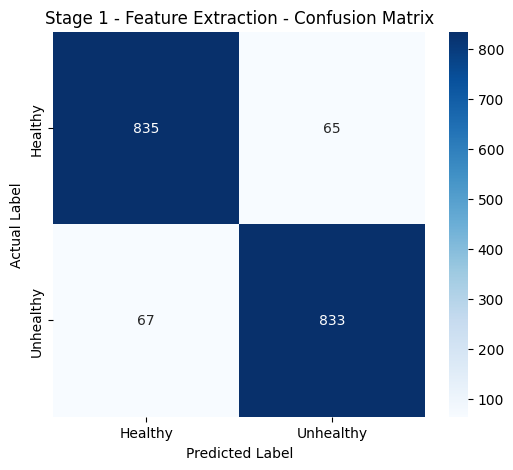


Stage 2 - Partial Fine-Tuning
Loss      : 0.0902
Accuracy  : 0.9717
Precision : 0.9680
Recall    : 0.9756
F1-score  : 0.9718

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.9754    0.9678    0.9716       900
   Unhealthy     0.9680    0.9756    0.9718       900

    accuracy                         0.9717      1800
   macro avg     0.9717    0.9717    0.9717      1800
weighted avg     0.9717    0.9717    0.9717      1800



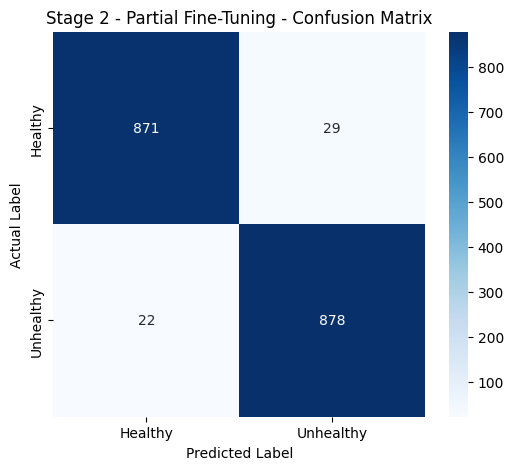


UNIFIED MODEL COMPARISON
                        Stage  Accuracy  Precision  Recall  F1-Score
 Stage 1 - Feature Extraction    0.9267     0.9276  0.9256    0.9266
Stage 2 - Partial Fine-Tuning    0.9717     0.9680  0.9756    0.9718


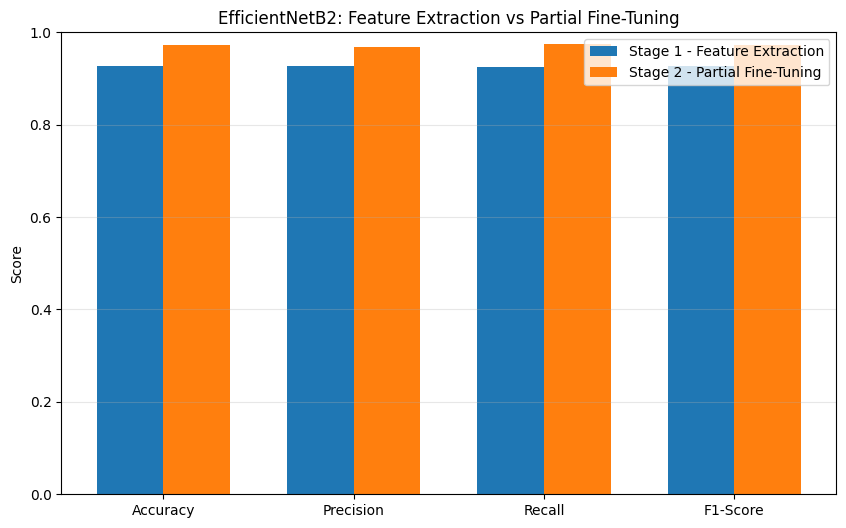

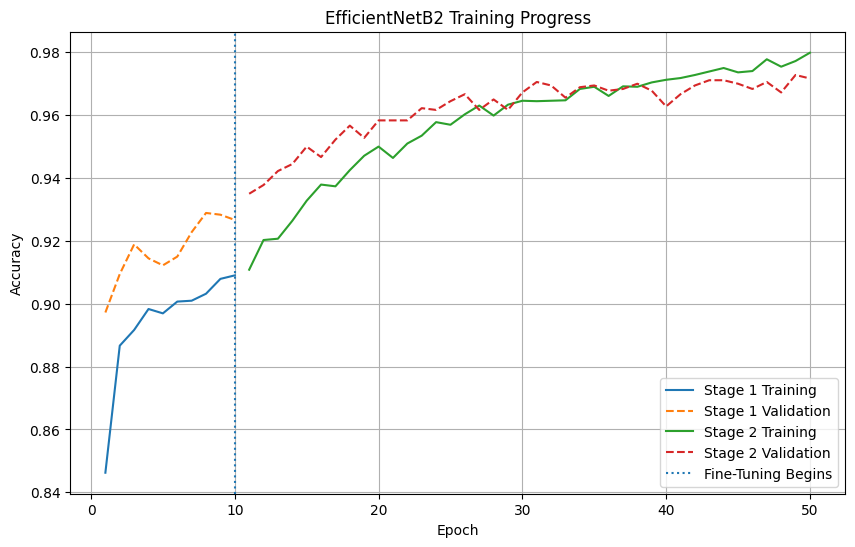

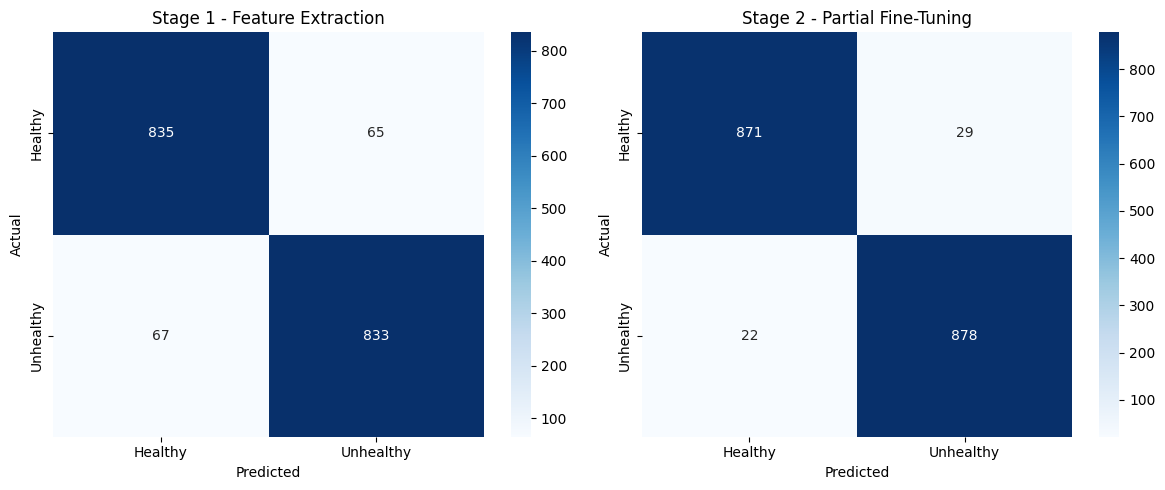

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


def evaluate_stage(model, loader, y_true, stage_name):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for images, _ in loader:
            logits = model(images.to(device, non_blocking=True))
            probabilities.extend(torch.sigmoid(logits).squeeze(1).cpu().numpy())

    probabilities = np.asarray(probabilities)
    y_pred = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_true).astype(int)
    loss, _ = run_epoch(model, loader, criterion)
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("\n" + "=" * 60)
    print(stage_name)
    print("=" * 60)
    print(f"Loss      : {loss:.4f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print("\nClassification Report:\n")
    print(classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"{stage_name} - Confusion Matrix")
    plt.show()
    return {
        "stage": stage_name,
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "y_pred": y_pred,
        "probabilities": probabilities,
        "confusion_matrix": cm,
    }


stage1_model = build_efficientnet_b2(pretrained=False).to(device)
stage1_model.load_state_dict(stage1_state_dict)
stage1_results = evaluate_stage(
    stage1_model, test_loader, y_test, "Stage 1 - Feature Extraction"
)
stage2_results = evaluate_stage(
    model, test_loader, y_test, "Stage 2 - Partial Fine-Tuning"
)

comparison = pd.DataFrame({
    "Stage": [
        "Stage 1 - Feature Extraction",
        "Stage 2 - Partial Fine-Tuning",
    ],
    "Accuracy": [stage1_results["accuracy"], stage2_results["accuracy"]],
    "Precision": [stage1_results["precision"], stage2_results["precision"]],
    "Recall": [stage1_results["recall"], stage2_results["recall"]],
    "F1-Score": [stage1_results["f1_score"], stage2_results["f1_score"]],
})
print("\n==============================================")
print("UNIFIED MODEL COMPARISON")
print("==============================================")
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
stage1_values = [
    stage1_results["accuracy"], stage1_results["precision"],
    stage1_results["recall"], stage1_results["f1_score"],
]
stage2_values = [
    stage2_results["accuracy"], stage2_results["precision"],
    stage2_results["recall"], stage2_results["f1_score"],
]
x = np.arange(len(metrics))
width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width / 2, stage1_values, width, label="Stage 1 - Feature Extraction")
plt.bar(x + width / 2, stage2_values, width, label="Stage 2 - Partial Fine-Tuning")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("EfficientNetB2: Feature Extraction vs Partial Fine-Tuning")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

stage1_epochs = range(1, len(history_stage1["accuracy"]) + 1)
stage2_epochs = range(
    len(history_stage1["accuracy"]) + 1,
    len(history_stage1["accuracy"]) + len(history_stage2["accuracy"]) + 1,
)
plt.figure(figsize=(10, 6))
plt.plot(stage1_epochs, history_stage1["accuracy"], label="Stage 1 Training")
plt.plot(stage1_epochs, history_stage1["val_accuracy"], linestyle="--", label="Stage 1 Validation")
plt.plot(stage2_epochs, history_stage2["accuracy"], label="Stage 2 Training")
plt.plot(stage2_epochs, history_stage2["val_accuracy"], linestyle="--", label="Stage 2 Validation")
plt.axvline(len(history_stage1["accuracy"]), linestyle=":", label="Fine-Tuning Begins")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB2 Training Progress")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, results, title in zip(
    axes,
    (stage1_results, stage2_results),
    ("Stage 1 - Feature Extraction", "Stage 2 - Partial Fine-Tuning"),
):
    sns.heatmap(
        results["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.tight_layout()
plt.show()